# Name matching: what each optimization saves

This notebook runs one name-matching task eight times on the same synthetic records. Each version adds one optimization
used in this project:

1. Baseline: all pairs, pure Python
2. Normalize each name once
3. Short-circuit evaluation
4. rapidfuzz string metrics (C++)
5. Vectorized scoring
6. Early termination
7. Blocking
8. DuckDB: native functions, parallel execution

Every version is checked against the baseline: it must return the same matched pairs with the same match level. For
sections 7 and 8, any match that blocking does not generate is listed. For each version the notebook reports wall time,
CPU time, the number of pairs compared and the number of string-metric calls, and projects the time to 1,000,000 records.

The records come from the project's generator (`er/generate.py`); no real data is used. The algorithms and their
settings come from `config/final.toml`. The task covers one comparison (person name). The last section starts from a
measured full run of the pipeline and estimates what the same run would cost without each optimization.

In [1]:
import logging
import math
import random
import time
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib_inline.backend_inline import set_matplotlib_formats
from rapidfuzz import process
from rapidfuzz.distance import DamerauLevenshtein, JaroWinkler

from er.candidates import candidates
from er.config import Comparator, column_name, keys_of, load_pipeline, q
from er.generate import generate, load_reference, load_spec
from er.settings import load_settings
from er.standardize import normalize, prepare
from er.strings import connect

logging.disable(logging.WARNING)
S = load_settings()
FINAL = load_pipeline(S.root / "config" / "final.toml", S.standardize, S.chains, S.columns)  # the tuned pipeline
UID = S.data.unique_id
pd.set_option("display.width", 200, "display.max_colwidth", 40)

BLUE, ORANGE, INK, INK2, MUTED, GRID, AXIS, SURFACE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
set_matplotlib_formats("svg")
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.edgecolor": AXIS,
                     "axes.linewidth": 0.8, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 10, "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": MUTED, "ytick.color": MUTED,
                     "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "font.size": 9, "legend.frameon": False, "figure.dpi": 100})

## Data

The input is the `person_name` field as built by `er/standardize.py` (`prepare`), plus the columns that the blocking
generators in section 7 use. The generator produces about 60,000 names.
Records are sorted by person, so the first N records contain complete groups of duplicates. Sections 1–6 use up to
3,600 records; sections 7 and 8 use up to all of them.

In [2]:
GENERATORS = ["person_name", "sn_person_name", "sn_person_name_reversed", "person_name_deletions_postal_area", "given_name_postal"]  # name generators in config/final.toml
FOLD = S.chains["fold"]  # kana folding
F, F1 = column_name("person_name", FOLD), column_name("person_name", (*FOLD, "one_byte"))
population = generate(replace(load_spec(S.root / "config" / "generator.toml")[0], entities=60_000), *load_reference(S.paths["reference"]))
PERSON = population.truth.set_index(UID)[S.data.entity_id]  # ground truth; used only to check the matches blocking misses
needed = {(k.column, k.normalize) for g in GENERATORS for k in keys_of(FINAL.generators[g]) if k.normalize}
needed |= {("person_name", (*FOLD, "one_byte"))}
RECORDS = prepare(S.standardize, population.df, sorted(needed), used={"person_name", "given_name", "postal_code"})
RECORDS = RECORDS[RECORDS["person_name"].notna()]
RECORDS = RECORDS.iloc[np.argsort(RECORDS[UID].map(PERSON).to_numpy(), kind="stable")].reset_index(drop=True)  # sorted by person
print(f"{len(RECORDS):,} records with a person name, for example:")
RECORDS[[UID, "person_name", "given_name", "postal_code"]].head(6)

59,135 records with a person name, for example:


,CONT_ID,person_name,given_name,postal_code
0,0000047418,ゴトウサナ,サナ,1330071
1,0000069634,ホンザワイツキ,イツキ,<NA>
2,0000045262,ブジマサオリ,サオリ,2510002
3,0000048396,フジマサオリ,<NA>,<NA>
4,0000016117,モリダジシ,ジシ,4440331
5,0000014628,ホンマシンイチロウ,シンイチロウ,2320025


## Reference implementations

The baseline uses plain-Python implementations of the three algorithms. They are checked against rapidfuzz (the library
the pipeline calls) and against the project's normalization on 5,000 pairs from this data.

- **Kana folding** maps small kana to full size and removes voicing marks (ョ → ヨ, ガ → カ).
- **Jaro–Winkler** is a similarity between 0 and 1, with extra weight on a common prefix of up to 4 characters.
- **Damerau–Levenshtein** is the minimum number of insertions, deletions, substitutions and adjacent transpositions.

In [3]:
KANA_FOLD = dict(S.standardize.kana_fold)


def fold(name: str) -> str:
    return "".join(KANA_FOLD.get(c, c) for c in name)


def jaro(a: str, b: str) -> float:
    if a == b:
        return 1.0
    if not a or not b:
        return 0.0
    window = max(max(len(a), len(b)) // 2 - 1, 0)
    used_a, used_b, matches = [False] * len(a), [False] * len(b), 0
    for i, c in enumerate(a):  # match characters within the window
        for j in range(max(0, i - window), min(len(b), i + window + 1)):
            if not used_b[j] and b[j] == c:
                used_a[i] = used_b[j] = True
                matches += 1
                break
    if not matches:
        return 0.0
    out_of_order, j = 0, 0
    for i in range(len(a)):  # count transpositions
        if used_a[i]:
            while not used_b[j]:
                j += 1
            out_of_order += a[i] != b[j]
            j += 1
    return (matches / len(a) + matches / len(b) + (matches - out_of_order // 2) / matches) / 3


def jaro_winkler(a: str, b: str) -> float:
    score = jaro(a, b)
    if score > 0.7:  # prefix bonus, up to 4 characters
        prefix = next((k for k, (x, y) in enumerate(zip(a[:4], b[:4])) if x != y), min(4, len(a), len(b)))
        score += prefix * 0.1 * (1 - score)
    return score


def damerau_levenshtein(a: str, b: str) -> int:  # unrestricted (Lowrance–Wagner), as in rapidfuzz
    last_row, inf = {}, len(a) + len(b)
    d = [[inf] * (len(b) + 2)] + [[inf] + [0] * (len(b) + 1) for _ in range(len(a) + 1)]
    for i in range(len(a) + 1):
        d[i + 1][1] = i
    for j in range(len(b) + 1):
        d[1][j + 1] = j
    for i in range(1, len(a) + 1):
        last_col = 0
        for j in range(1, len(b) + 1):
            i1, j1, cost = last_row.get(b[j - 1], 0), last_col, a[i - 1] != b[j - 1]
            if not cost:
                last_col = j
            d[i + 1][j + 1] = min(d[i][j] + cost, d[i + 1][j] + 1, d[i][j + 1] + 1, d[i1][j1] + (i - i1 - 1) + 1 + (j - j1 - 1))
        last_row[a[i - 1]] = i
    return d[len(a) + 1][len(b) + 1]


rnd, names = random.Random(0), RECORDS["person_name"].tolist()
for _ in range(5_000):
    a, b = rnd.choice(names), rnd.choice(names)
    if rnd.random() < 0.3:  # include near-duplicates
        b = a[:-1] + rnd.choice(a)
    fa, fb = fold(a), fold(b)
    assert abs(jaro_winkler(fa, fb) - JaroWinkler.similarity(fa, fb)) < 1e-12 and damerau_levenshtein(fa, fb) == DamerauLevenshtein.distance(fa, fb)
assert normalize(RECORDS["person_name"], FOLD, S.standardize).tolist() == [fold(x) for x in names]
print("reference implementations agree with rapidfuzz and with the project's normalization")

reference implementations agree with rapidfuzz and with the project's normalization


## Match criteria

A pair is assigned the first level that holds. These are the person-name levels of the model and the one-edit test used
by the rules.

| Level | Condition |
|---|---|
| exact | names are equal |
| fold exact | names are equal after folding |
| very similar | Jaro–Winkler of the folded names ≥ 0.95 |
| one edit apart | Damerau–Levenshtein of the folded names = 1 |

Pairs that meet none of them are not matches. The pipeline stores scores as 32-bit floats before comparing them with a
threshold, so a score of exactly 0.95 becomes 0.9499999… and fails 0.95. Every version compares the same way
(`at_least`).

In [4]:
LEVELS = ["exact", "fold exact", "very similar", "one edit apart"]
VERY_SIMILAR, EDITS = 0.95, 1


def at_least(score, threshold: float) -> bool:  # the pipeline compares the 32-bit score with the threshold
    return float(np.float32(score)) >= threshold


def shown(answer: dict, recs: pd.DataFrame, rows: int = 6) -> pd.DataFrame:  # sample of matched pairs per level
    name = dict(zip(recs[UID], recs["person_name"]))
    pairs = pd.DataFrame([(a, b, name[a], name[b], LEVELS[s]) for (a, b), s in answer.items()], columns=["record A", "record B", "name A", "name B", "level"])
    return pairs.groupby("level", sort=False, group_keys=False).head(2).head(rows)


LEDGER = []  # one row per section and size
CHECK = 1_200  # every section's result at this size is compared with the baseline
BASELINE = {}


def measure(section: int, title: str, answer, sizes: list[int], big_o: str):
    """Run answer(records) at each size and record its cost. answer returns ({(id, id): level}, pairs compared,
    string-metric calls). Each size is timed twice and the faster run is kept. At CHECK records the result is compared
    with the baseline."""
    rows = []
    for n in sorted({*sizes, CHECK}):
        recs, wall, cpu = RECORDS.head(n), math.inf, math.inf
        for _ in range(2):
            t, c = time.perf_counter(), time.process_time()
            got, pairs, calls = answer(recs)
            wall, cpu = min(wall, time.perf_counter() - t), min(cpu, time.process_time() - c)
        got = {tuple(sorted(k)): v for k, v in got.items()}  # order-independent pair key
        same = None
        if n == CHECK:
            if section == 1:
                BASELINE.update(got)
            same = got == BASELINE
        rows.append(dict(section=section, title=title, records=n, wall=wall, cpu=cpu, pairs=pairs, calls=calls, matches=len(got), same=same, answer=got))
    LEDGER.extend(rows)
    table = pd.DataFrame(rows).drop(columns="answer")
    matched = table.loc[table.records == CHECK, "same"].item()
    print(f"{big_o}. Result at {CHECK:,} records {'matches' if matched else 'differs from'} the baseline.")
    return table.style.format({"wall": "{:.3f} s", "cpu": "{:.3f} s", "pairs": "{:,}", "calls": lambda v: "" if v is None or pd.isna(v) else f"{v:,.0f}",
                               "records": "{:,}", "matches": "{:,}", "same": lambda v: {True: "yes", False: "no"}.get(v, "")}).hide(axis="index")

## 1 · Baseline: all pairs, pure Python

Compares all N·(N−1)/2 pairs. For each pair it folds both names and runs all four tests. Cost: O(N²·L²) for N records
and names of length L. `calls` counts Jaro–Winkler and Damerau–Levenshtein calls.

In [5]:
def answer_1(recs: pd.DataFrame):
    ids, names, out, calls = recs[UID].tolist(), recs["person_name"].tolist(), {}, 0
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            a, b = names[i], names[j]
            tests = [a == b, fold(a) == fold(b), at_least(jaro_winkler(fold(a), fold(b)), VERY_SIMILAR), damerau_levenshtein(fold(a), fold(b)) <= EDITS]
            calls += 2
            level = next((k for k, holds in enumerate(tests) if holds), None)
            if level is not None:
                out[(ids[i], ids[j])] = level
    return out, len(names) * (len(names) - 1) // 2, calls


display(measure(1, "baseline", answer_1, [300, 600], "O(N²·L²)"))
shown(BASELINE, RECORDS.head(CHECK))

O(N²·L²). Result at 1,200 records matches the baseline.


section,title,records,wall,cpu,pairs,calls,matches,same
1,baseline,300,0.824 s,0.823 s,"44,850","89,700",45,
1,baseline,600,3.254 s,3.243 s,"179,700","359,400",107,
1,baseline,"1,200",12.946 s,12.909 s,"719,400","1,438,800",236,yes


,record A,record B,name A,name B,level
0,0000045262,0000048396,ブジマサオリ,フジマサオリ,fold exact
1,0000013499,0000045439,カワシママナカ,カワシママナカ,exact
2,0000007476,0000032178,アカツカメエミ,アカツカメイエミ,very similar
3,0000004053,0000028028,ムラカミヤスノリ,ムラカミヤスノリ,exact
4,0000040807,0000058059,ヨコタドモヒデ,ヨコタトモヒデ,fold exact
9,0000030030,0000046886,タカハシカスミ,タカハシガズコ,one edit apart


## 2 · Normalize each name once

Folds every name once before the pair loop. The pipeline does this in `er/standardize.py` and caches the prepared
records in the workspace (`prepared/`). Folding drops from O(N²·L) to O(N·L); the scores are unchanged.

In [6]:
def answer_2(recs: pd.DataFrame):
    ids, names, out, calls = recs[UID].tolist(), recs["person_name"].tolist(), {}, 0
    folded = [fold(x) for x in names]
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            a, b, fa, fb = names[i], names[j], folded[i], folded[j]
            tests = [a == b, fa == fb, at_least(jaro_winkler(fa, fb), VERY_SIMILAR), damerau_levenshtein(fa, fb) <= EDITS]
            calls += 2
            level = next((k for k, holds in enumerate(tests) if holds), None)
            if level is not None:
                out[(ids[i], ids[j])] = level
    return out, len(names) * (len(names) - 1) // 2, calls


measure(2, "normalize once", answer_2, [300, 600], "O(N·L + N²·L²)")

O(N·L + N²·L²). Result at 1,200 records matches the baseline.


section,title,records,wall,cpu,pairs,calls,matches,same
2,normalize once,300,0.657 s,0.654 s,"44,850","89,700",45,
2,normalize once,600,2.627 s,2.621 s,"179,700","359,400",107,
2,normalize once,"1,200",10.469 s,10.439 s,"719,400","1,438,800",236,yes


## 3 · Short-circuit evaluation

Runs the tests from cheapest to most expensive and stops at the first that passes. The pipeline writes each comparison as
a SQL `CASE` expression (`Comparator` in `er/config.py`), which DuckDB evaluates in order. For names the gain is small:
few pairs are equal, so nearly every pair still needs Jaro–Winkler. The technique matters more for fields where an exact
check decides most pairs.

In [7]:
def answer_3(recs: pd.DataFrame):
    ids, names, out, calls = recs[UID].tolist(), recs["person_name"].tolist(), {}, 0
    folded = [fold(x) for x in names]
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            a, b, fa, fb = names[i], names[j], folded[i], folded[j]
            if a == b:
                out[(ids[i], ids[j])] = 0
            elif fa == fb:
                out[(ids[i], ids[j])] = 1
            else:
                calls += 1
                if at_least(jaro_winkler(fa, fb), VERY_SIMILAR):
                    out[(ids[i], ids[j])] = 2
                else:
                    calls += 1
                    if damerau_levenshtein(fa, fb) <= EDITS:
                        out[(ids[i], ids[j])] = 3
    return out, len(names) * (len(names) - 1) // 2, calls


measure(3, "short-circuit", answer_3, [300, 600], "O(N·L + N²·L²), fewer calls")

O(N·L + N²·L²), fewer calls. Result at 1,200 records matches the baseline.


section,title,records,wall,cpu,pairs,calls,matches,same
3,short-circuit,300,0.653 s,0.652 s,"44,850","89,619",45,
3,short-circuit,600,2.600 s,2.593 s,"179,700","359,221",107,
3,short-circuit,"1,200",10.412 s,10.384 s,"719,400","1,438,435",236,yes


## 4 · rapidfuzz string metrics

Replaces the Python implementations with rapidfuzz, a C++ library with bit-parallel algorithms (`FUNCTIONS` in
`er/strings.py`). The scores and the complexity are the same; the cost per call is much lower.

In [8]:
def answer_4(recs: pd.DataFrame):
    ids, names, out, calls = recs[UID].tolist(), recs["person_name"].tolist(), {}, 0
    folded = [fold(x) for x in names]
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            a, b, fa, fb = names[i], names[j], folded[i], folded[j]
            if a == b:
                out[(ids[i], ids[j])] = 0
            elif fa == fb:
                out[(ids[i], ids[j])] = 1
            else:
                calls += 1
                if at_least(JaroWinkler.similarity(fa, fb), VERY_SIMILAR):
                    out[(ids[i], ids[j])] = 2
                else:
                    calls += 1
                    if DamerauLevenshtein.distance(fa, fb) <= EDITS:
                        out[(ids[i], ids[j])] = 3
    return out, len(names) * (len(names) - 1) // 2, calls


measure(4, "rapidfuzz", answer_4, [2_400, 3_600], "O(N·L + N²·L²), compiled")

O(N·L + N²·L²), compiled. Result at 1,200 records matches the baseline.


section,title,records,wall,cpu,pairs,calls,matches,same
4,rapidfuzz,"1,200",0.581 s,0.580 s,"719,400","1,438,435",236,yes
4,rapidfuzz,"2,400",2.344 s,2.338 s,"2,878,800","5,756,775",536,
4,rapidfuzz,"3,600",5.298 s,5.282 s,"6,478,200","12,955,122",855,


## 5 · Vectorized scoring

Scores all remaining pairs in one call (`process.cpdist`, as `udf` in `er/strings.py` does) instead of one Python call
per pair, which removes the per-call interpreter overhead. Each test runs only on the pairs that earlier tests did not
decide.

In [9]:
def levels_of(recs: pd.DataFrame, left: np.ndarray, right: np.ndarray, early_exit: bool = False):
    """Match level for each pair (left[k], right[k] are row positions in recs), computed on arrays. With early_exit,
    rapidfuzz stops at the threshold and pairs whose lengths differ by more than EDITS are skipped."""
    ids, names = recs[UID].to_numpy(object), recs["person_name"].to_numpy(object)
    folded = np.array([fold(x) for x in names], dtype=object)
    level = np.full(len(left), -1)
    level[names[left] == names[right]] = 0
    level[(level < 0) & (folded[left] == folded[right])] = 1
    rest = np.flatnonzero(level < 0)
    cutoff = {"score_cutoff": VERY_SIMILAR - 1e-6} if early_exit else {}  # slightly below the threshold, as in er/strings.py, because scores are 32-bit
    similarity = process.cpdist(folded[left[rest]].tolist(), folded[right[rest]].tolist(), scorer=JaroWinkler.similarity, workers=1, **cutoff)
    calls = len(rest)
    level[rest[similarity.astype(np.float64) >= VERY_SIMILAR]] = 2  # same comparison as at_least
    rest = np.flatnonzero(level < 0)
    if early_exit:
        lengths = np.array([len(x) for x in folded])
        rest = rest[np.abs(lengths[left[rest]] - lengths[right[rest]]) <= EDITS]
    edits = process.cpdist(folded[left[rest]].tolist(), folded[right[rest]].tolist(), scorer=DamerauLevenshtein.distance, workers=1,
                           **({"score_cutoff": EDITS} if early_exit else {}))
    calls += len(rest)
    level[rest[edits <= EDITS]] = 3
    keep = level >= 0
    return dict(zip(zip(ids[left[keep]], ids[right[keep]]), level[keep].tolist())), len(left), calls


def answer_5(recs: pd.DataFrame):
    left, right = np.triu_indices(len(recs), 1)  # all pairs
    return levels_of(recs, left, right)


measure(5, "vectorized", answer_5, [2_400, 3_600], "O(N·L + N²·L²), loop in C++")

O(N·L + N²·L²), loop in C++. Result at 1,200 records matches the baseline.


section,title,records,wall,cpu,pairs,calls,matches,same
5,vectorized,"1,200",0.405 s,0.404 s,"719,400","1,438,435",236,yes
5,vectorized,"2,400",1.632 s,1.627 s,"2,878,800","5,756,775",536,
5,vectorized,"3,600",3.718 s,3.706 s,"6,478,200","12,955,122",855,


## 6 · Early termination

Passes the threshold to rapidfuzz (`score_cutoff`), so the edit-distance computation stops once the distance exceeds 1.
Pairs whose lengths differ by more than 1 are skipped. The results are identical; the project tests this in
`test_a_comparison_told_its_threshold_passes_and_fails_the_pairs_the_full_score_does`. The edit distance costs O(L·k)
for threshold k instead of O(L²).

In [10]:
def answer_6(recs: pd.DataFrame):
    left, right = np.triu_indices(len(recs), 1)
    return levels_of(recs, left, right, early_exit=True)


measure(6, "early termination", answer_6, [2_400, 3_600], "O(N·L + N²·L·k)")

O(N·L + N²·L·k). Result at 1,200 records matches the baseline.


section,title,records,wall,cpu,pairs,calls,matches,same
6,early termination,"1,200",0.280 s,0.279 s,"719,400","1,191,964",236,yes
6,early termination,"2,400",1.134 s,1.131 s,"2,878,800","4,774,569",536,
6,early termination,"3,600",2.551 s,2.545 s,"6,478,200","10,768,805",855,


## 7 · Blocking

Comparing all pairs is O(N²): 5 × 10¹¹ pairs at 1,000,000 records. Blocking generates a much smaller set of candidate
pairs and scores only those (`er/candidates.py`). These are the name generators in `config/final.toml`:

- `person_name`: same folded name
- `sn_person_name`, `sn_person_name_reversed`: sorted-neighbourhood window of 4 on the folded name and on its reverse
- `person_name_deletions_postal_area`: same postal area, and names that become equal after deleting one character
- `given_name_postal`: same given name and postal code

Generating the candidates costs about O(N·L·log N), and scoring them O(C·L·k) for C candidate pairs. On the project's
synthetic benchmark these generators produce about 6.7 pairs per record at 1,000,000 records (`docs/results.md`).

Blocking can miss matches. The cell lists every baseline match that no generator produced and uses the generator's
ground truth to check whether the two records belong to the same person. In a full run, the probe step (`er/probe.py`)
estimates how many matches blocking missed.

In [11]:
def candidate_pairs(recs: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    pairs, _ = candidates(tuple(FINAL.generators[g] for g in GENERATORS), recs, UID, None, FINAL.fs.budget)
    row = pd.Series(np.arange(len(recs)), index=recs[UID])
    left, right = row[pairs[f"{UID}_l"]].to_numpy(), row[pairs[f"{UID}_r"]].to_numpy()
    return np.minimum(left, right), np.maximum(left, right)


def answer_7(recs: pd.DataFrame):
    return levels_of(recs, *candidate_pairs(recs), early_exit=True)


display(measure(7, "blocking", answer_7, [10_000, 40_000, len(RECORDS)], "O(N·L·log N + C·L·k)"))
got = next(r["answer"] for r in LEDGER if r["section"] == 7 and r["records"] == CHECK)
missed = {k: v for k, v in BASELINE.items() if k not in got}
assert all(BASELINE[k] == v for k, v in got.items())  # generated pairs get the baseline's level
same_person = sum(PERSON[a] == PERSON[b] for a, b in missed)
print(f"Baseline: {len(BASELINE):,} matches. Blocking: {len(got):,}. Not generated: {len(missed):,}, "
      f"of which {same_person} belong to the same person (ground truth).")
shown(missed, RECORDS.head(CHECK), rows=10)

O(N·L·log N + C·L·k). Result at 1,200 records differs from the baseline.


section,title,records,wall,cpu,pairs,calls,matches,same
7,blocking,"1,200",0.041 s,0.056 s,"6,986","11,681",235,no
7,blocking,"10,000",0.145 s,0.188 s,"58,306","99,150","2,632",
7,blocking,"40,000",0.437 s,0.638 s,"233,003","399,849","15,937",
7,blocking,"59,135",0.633 s,1.036 s,"344,063","590,994","27,352",


Baseline: 236 matches. Blocking: 235. Not generated: 1, of which 0 belong to the same person (ground truth).


,record A,record B,name A,name B,level
0,0000011089,0000052290,スズキナ,スズキセ,one edit apart


**TF-IDF nearest neighbours** (`tfidf_person_name`) is defined in the project but not used in `config/final.toml`.
Its implementation compares each name with every other name, which is O(N²); `docs/results.md` lists it at 1,000,000
pairs per record at 1,000,000 records. Its cost and recall on the same records:

In [12]:
recs = RECORDS.head(CHECK)
t = time.perf_counter()
tfidf, _ = candidates((FINAL.generators["tfidf_person_name"],), recs, UID, None, FINAL.fs.budget)
seconds = time.perf_counter() - t
row = pd.Series(np.arange(len(recs)), index=recs[UID])
l, r = row[tfidf[f"{UID}_l"]].to_numpy(), row[tfidf[f"{UID}_r"]].to_numpy()
found, _, _ = levels_of(recs, np.minimum(l, r), np.maximum(l, r), early_exit=True)
found = {tuple(sorted(k)): v for k, v in found.items()}
print(f"TF-IDF: {len(tfidf):,} candidate pairs in {seconds:.2f} s at {CHECK:,} records. "
      f"It generates {len(set(found) & set(missed))} of the {len(missed)} matches that section 7 misses.")

TF-IDF: 311 candidate pairs in 0.68 s at 1,200 records. It generates 0 of the 1 matches that section 7 misses.


## 8 · DuckDB: native functions, parallel execution

Runs the same tests on the same candidate pairs in DuckDB, using the SQL the pipeline generates (`Comparator.test` in
`er/config.py`). DuckDB executes on all cores and keeps the data in columnar form inside the database. For names that
are all katakana, Jaro–Winkler uses DuckDB's built-in `jaro_winkler_similarity` on a copy of the name with one byte per
character (the `one_byte` normalizer), so that test runs without Python. Damerau–Levenshtein still calls the Python UDF
(`cl_damerau_levenshtein_cut`), only for pairs that pass the length filter.

At 1,200 records the fixed cost of creating the connection and tables is about as large as the work itself, so this
version is not faster than section 7 there. The difference shows at the larger sizes.

In [13]:
SIMILAR, EDIT = Comparator("jaro_winkler", VERY_SIMILAR, FOLD), Comparator("damerau_levenshtein", EDITS, FOLD)
side = lambda t, c: f"{t}.{q(c)}"


def answer_8(recs: pd.DataFrame):
    con, _ = connect({})  # DuckDB connection with the project's UDFs registered
    con.register("recs_frame", recs)
    con.execute("CREATE TABLE recs AS SELECT * FROM recs_frame")
    candidates(tuple(FINAL.generators[g] for g in GENERATORS), "recs", UID, None, FINAL.fs.budget, con=con, into="cands")
    rows = con.execute(f"""SELECT a, b, level FROM (SELECT c.{q(UID + '_l')} AS a, c.{q(UID + '_r')} AS b,
            CASE WHEN l.person_name = r.person_name THEN 0 WHEN {side('l', F)} = {side('r', F)} THEN 1
                 WHEN {SIMILAR.test(side('l', F), side('r', F), side('l', F1), side('r', F1))} THEN 2
                 WHEN {EDIT.test(side('l', F), side('r', F))} THEN 3 END AS level
        FROM cands c JOIN recs l ON l.{q(UID)} = c.{q(UID + '_l')} JOIN recs r ON r.{q(UID)} = c.{q(UID + '_r')}) WHERE level IS NOT NULL""").fetchall()
    pairs = con.execute("SELECT count(*) FROM cands").fetchone()[0]
    con.close()
    return {(a, b): s for a, b, s in rows}, pairs, None  # string-metric calls are the same as in section 7


display(measure(8, "DuckDB", answer_8, [10_000, 40_000, len(RECORDS)], "O(N·L·log N + C·L·k) / cores"))
eighth = next(r["answer"] for r in LEDGER if r["section"] == 8 and r["records"] == CHECK)
print("Same result as section 7:", eighth == got)

O(N·L·log N + C·L·k) / cores. Result at 1,200 records differs from the baseline.


section,title,records,wall,cpu,pairs,calls,matches,same
8,DuckDB,"1,200",0.048 s,0.065 s,"6,986",,235,no
8,DuckDB,"10,000",0.139 s,0.188 s,"58,306",,"2,632",
8,DuckDB,"40,000",0.385 s,0.630 s,"233,003",,"15,937",
8,DuckDB,"59,135",0.566 s,1.068 s,"344,063",,"27,352",


Same result as section 7: True


## Summary

Wall time at 1,200 records, and projected wall time at 1,000,000 records. The projection is a linear fit of wall time
against the number of pairs compared, over each section's measured sizes, evaluated at 5 × 10¹¹ pairs (sections 1–6) or
at 6.7 pairs per record (sections 7–8). It is an extrapolation. At 1,200 records the fixed setup cost of blocking and of
DuckDB, a few hundredths of a second, is most of the time of sections 7 and 8.

In [14]:
PER_RECORD_AT_1M = 0.609 + 3.0 + 3.0 + 0.081 + 0.055  # pairs per record at 1M for the five generators (docs/results.md)
MILLION = 1_000_000
ledger = pd.DataFrame(LEDGER).drop(columns="answer")


def fit(rows: pd.DataFrame) -> tuple[float, float]:  # seconds = fixed + per_pair · pairs, least squares over the measured sizes
    per_pair, fixed = np.polyfit(rows["pairs"], rows["wall"], 1)
    return max(fixed, 0.0), max(per_pair, 0.0)


def at_a_million(rows: pd.DataFrame) -> float:
    fixed, per_pair = fit(rows)
    pairs = MILLION * (MILLION - 1) / 2 if rows["section"].iloc[0] <= 6 else PER_RECORD_AT_1M * MILLION
    return fixed + per_pair * pairs


def readable(seconds: float) -> str:
    for unit, size in (("years", 365 * 86400), ("days", 86400), ("hours", 3600), ("minutes", 60)):
        if seconds >= 2 * size:
            x = seconds / size
            return f"{x:,.1f} {unit}" if x < 10 else f"{x:,.0f} {unit}"
    return f"{seconds:,.0f} seconds" if seconds >= 2 else f"{seconds:.1f} seconds"


summary = ledger[ledger.records == CHECK].set_index("section")[["title", "wall", "cpu", "pairs", "calls", "matches", "same"]]
summary["speed-up vs previous"] = (summary["wall"].shift() / summary["wall"]).map(lambda x: "" if pd.isna(x) else f"{x:,.1f}×")
summary["projected at 1M (s)"] = [at_a_million(ledger[ledger.section == s]) for s in summary.index]
summary["projected at 1M"] = summary["projected at 1M (s)"].map(readable)
summary["same"] = summary["same"].map({True: "yes", False: f"{len(missed)} not generated (section 7)"})
summary = summary.rename(columns={"same": "matches baseline"})
summary.style.format({"wall": "{:.3f} s", "cpu": "{:.3f} s", "pairs": "{:,}", "calls": lambda v: "" if pd.isna(v) else f"{v:,.0f}",
                      "projected at 1M (s)": "{:,.0f}"})

,title,wall,cpu,pairs,calls,matches,matches baseline,speed-up vs previous,projected at 1M (s),projected at 1M
section,,,,,,,,,,
1,baseline,12.946 s,12.909 s,"719,400","1,438,800",236,yes,,"8,983,235",104 days
2,normalize once,10.469 s,10.439 s,"719,400","1,438,800",236,yes,1.2×,"7,271,080",84 days
3,short-circuit,10.412 s,10.384 s,"719,400","1,438,435",236,yes,1.0×,"7,234,230",84 days
4,rapidfuzz,0.581 s,0.580 s,"719,400","1,438,435",236,yes,17.9×,"409,608",4.7 days
5,vectorized,0.405 s,0.404 s,"719,400","1,438,435",236,yes,1.4×,"287,858",3.3 days
6,early termination,0.280 s,0.279 s,"719,400","1,191,964",236,yes,1.4×,"197,099",2.3 days
7,blocking,0.041 s,0.056 s,"6,986","11,681",235,1 not generated (section 7),6.8×,12,12 seconds
8,DuckDB,0.048 s,0.065 s,"6,986",,235,1 not generated (section 7),0.9×,10,10 seconds


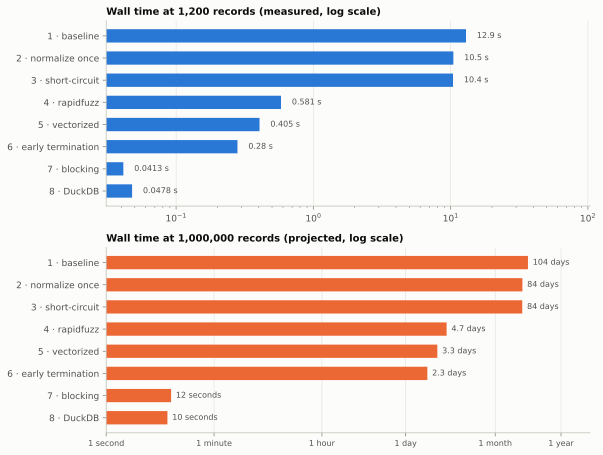

In [15]:
fig, (here, there) = plt.subplots(2, 1, figsize=(8.5, 6.4))
labels = [f"{s} · {t}" for s, t in zip(summary.index, summary["title"])]
for ax, values, colour, title in ((here, summary["wall"], BLUE, f"Wall time at {CHECK:,} records (measured, log scale)"),
                                  (there, summary["projected at 1M (s)"], ORANGE, "Wall time at 1,000,000 records (projected, log scale)")):
    ax.barh(labels, values, color=colour, height=0.6)
    ax.set_xscale("log")
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
for y, v in enumerate(summary["wall"]):
    here.text(v * 1.2, y, f"{v:.3g} s", va="center", color=INK2, fontsize=8)
for y, (v, s) in enumerate(zip(summary["projected at 1M (s)"], summary["projected at 1M"])):
    there.text(v * 1.2, y, s, va="center", color=INK2, fontsize=8)
here.set_xlim(right=summary["wall"].max() * 8)
ticks = {"1 second": 1, "1 minute": 60, "1 hour": 3600, "1 day": 86400, "1 month": 30 * 86400, "1 year": 365 * 86400}
there.set_xticks(list(ticks.values()), list(ticks), fontsize=8)
there.set_xticks([], minor=True)
there.set_xlim(1, ticks["1 year"] * 3)
fig.tight_layout()
plt.show()

## Projecting a full run

The summary covers one comparison on one short field. A full run (`nayose resolve records`) also compares company name,
address, phone, customer ID and birth date, uses 21 candidate generators, and runs other steps: reading and cleaning
the file, block budgeting, model fitting, rules, the probe, clustering and reports. On real files there are usually
more candidate pairs per record than on synthetic data, because frequent values (shared phone digits, the same address
code, common names) create large blocks, and fields such as addresses are longer than names.

This section starts from a measured full run and estimates what the same run would cost without each optimization:

- the run's measured wall time T, its records N and its candidate pairs C;
- each version adds the extra string-comparison work: K comparisons per pair (6), at the cost per comparison measured in
  sections 1–8, on C pairs (sections 7–8) or on all N·(N−1)/2 pairs (sections 1–6, no blocking);
- steps that do not compare strings are left unchanged.

The per-comparison costs are measured on names of about 7 characters. Longer fields make the unoptimized versions
slower still (their cost grows with L²), so the estimates for the slower versions are lower bounds.

By default the cell runs the pipeline on this notebook's synthetic records and uses that run. To project another run,
set `RUN` to its numbers from its `report.txt` (records, candidate pairs scored, total time).

In [16]:
import contextlib
import io
import json
import tempfile
from pathlib import Path

from er.cli import main as nayose

RUN = None  # another run: dict(records=..., candidate_pairs=..., hours=...); None runs the pipeline on the synthetic records here

if RUN is None:
    with tempfile.TemporaryDirectory() as tmp:
        population.df.to_parquet(f"{tmp}/records.parquet", index=False)
        with contextlib.redirect_stdout(io.StringIO()):
            assert nayose(["resolve", "records", f"{tmp}/records.parquet", "--workspace", f"{tmp}/run", "--format", "json"]) == 0
        steps = json.loads(Path(f"{tmp}/run/steps.json").read_text(encoding="utf-8"))["runs"][-1]["steps"]
    step = {s["step"]: s for s in steps}
    RUN = dict(records=step["load"]["records"], candidate_pairs=step["candidates"]["candidates"], hours=sum(s["seconds"] for s in steps) / 3600)
    display(pd.DataFrame([(s["step"], s["seconds"]) for s in steps], columns=["step", "seconds"]).set_index("step").T)
print(f"Run: {RUN['records']:,} records, {RUN['candidate_pairs']:,} candidate pairs, {readable(RUN['hours'] * 3600)}.")

step,load,budget,fit,rules,candidates,score,cluster,probe,report,write
seconds,1.43,0.54,6.16,0.31,1.08,0.67,0.1,1.56,0.35,0.31


Run: 74,959 records, 403,409 candidate pairs, 13 seconds.


In [17]:
COMPARISONS = len(FINAL.fs.model.comparisons)  # comparisons per candidate pair in a full run
per_pair = {s: fit(ledger[ledger.section == s])[1] for s in range(1, 9)}  # seconds per pair, one comparison, from the fits above
N, C, T = RUN["records"], RUN["candidate_pairs"], RUN["hours"] * 3600
versions = [("measured run", 8), ("without DuckDB native functions", 7), ("also without blocking", 6), ("also without early termination", 5),
            ("also without vectorized scoring", 4), ("also without rapidfuzz", 3), ("also without short-circuit evaluation", 2),
            ("also without normalizing once (baseline)", 1)]
rows = []
for label, s in versions:
    pairs = C if s >= 7 else N * (N - 1) / 2
    seconds = T + COMPARISONS * (pairs * per_pair[s] - C * per_pair[8])
    rows.append(dict(version=label, section=s, pairs_compared=pairs, seconds=seconds, time=readable(seconds), vs_measured=f"{seconds / T:,.0f}×"))
projection = pd.DataFrame(rows).set_index("version")
projection.style.format({"pairs_compared": "{:,.0f}", "seconds": "{:,.0f}"})

,section,pairs_compared,seconds,time,vs_measured
version,,,,,
measured run,8,"403,409",13,13 seconds,1×
without DuckDB native functions,7,"403,409",13,13 seconds,1×
also without blocking,6,"2,809,388,361","6,654",111 minutes,532×
also without early termination,5,"2,809,388,361","9,713",2.7 hours,776×
also without vectorized scoring,4,"2,809,388,361","13,818",3.8 hours,"1,105×"
also without rapidfuzz,3,"2,809,388,361","243,894",2.8 days,"19,496×"
also without short-circuit evaluation,2,"2,809,388,361","245,137",2.8 days,"19,595×"
also without normalizing once (baseline),1,"2,809,388,361","302,858",3.5 days,"24,209×"


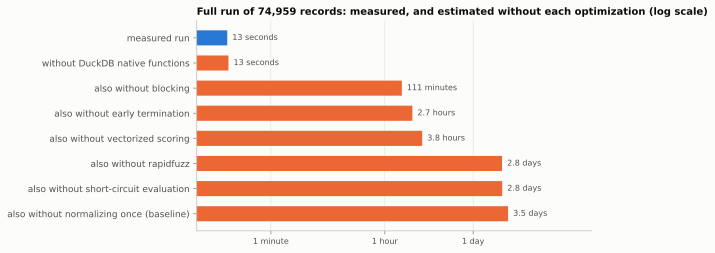

In [18]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.barh(projection.index, projection["seconds"], color=[BLUE] + [ORANGE] * (len(projection) - 1), height=0.6)
ax.set_xscale("log")
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_title(f"Full run of {N:,} records: measured, and estimated without each optimization (log scale)")
for y, (v, s) in enumerate(zip(projection["seconds"], projection["time"])):
    ax.text(v * 1.2, y, s, va="center", color=INK2, fontsize=8)
ticks = {"1 minute": 60, "1 hour": 3600, "1 day": 86400, "1 month": 30 * 86400, "1 year": 365 * 86400, "10 years": 3650 * 86400}
shown_ticks = {k: v for k, v in ticks.items() if v <= projection["seconds"].max() * 3}
ax.set_xticks(list(shown_ticks.values()), list(shown_ticks), fontsize=8)
ax.set_xticks([], minor=True)
ax.set_xlim(projection["seconds"].min() / 3, projection["seconds"].max() * 20)
fig.tight_layout()
plt.show()

Blocking accounts for most of the difference: without it, the number of pairs is N·(N−1)/2 whatever the data, and
the comparison work grows with the square of the number of records. The compiled string metrics account for most of the
rest. The optimizations that look small on names (normalizing once, short-circuit evaluation) save more on long fields
and on fields where an exact check decides most pairs.